# Émissions de CO₂ des voitures neuves en France (2022–2024)

**Question :** comment les émissions moyennes homologuées évoluent-elles, et comment les écarts départementaux sont-ils associés aux motorisations ?

**Résultats à retenir.** La moyenne nationale, pondérée par les immatriculations, passe de **102,70 à 93,58 g/km** entre 2022 et 2024 (−9,11 g/km). La part « électrique et hydrogène » progresse de **13,15 % à 16,84 %** (+3,69 points). Les écarts territoriaux restent marqués. L'association entre part électrique et CO₂ est descriptive : elle ne démontre pas à elle seule une causalité.

Sources : [SDES — motorisations](https://www.data.gouv.fr/datasets/part-de-voitures-particulieres-vp-neuves-par-source-denergie) ; [SDES — émissions](https://www.data.gouv.fr/datasets/emissions-moyennes-de-co2-des-voitures-particulieres-neuves-tout-carburant) ; [Etalab — contours administratifs 2024](https://etalab-datasets.geo.data.gouv.fr/contours-administratifs/2024/geojson/). Fichiers archivés dans `data/raw/` ; tableau consolidé dans `data/processed/`.

## 1. Lecture, nettoyage et contrôles

Les codes départementaux sont lus comme du texte. Les sept motorisations sont réunies en cinq groupes non chevauchants. Les parts sont recalculées sur les effectifs, pour éviter les écarts d'arrondi des pourcentages publiés. La jointure est contrôlée sur **année + code département** ; les dénominateurs des deux sources doivent être identiques.

In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from prepare_data import RAW, OUT, load_and_validate, national

plt.rcParams.update({"figure.figsize": (9, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
motorisations, emissions, tableau = load_and_validate()
OUT.parent.mkdir(parents=True, exist_ok=True)
tableau.to_csv(OUT, index=False, float_format="%.10f")
national_ = national(tableau)
print(f"Motorisations : {len(motorisations):,} lignes, {motorisations.annee.min()}–{motorisations.annee.max()}")
print(f"Émissions : {len(emissions):,} lignes, {emissions.annee.min()}–{emissions.annee.max()}")
print(f"Tableau consolidé : {len(tableau)} couples département–année ; {tableau.geocode_departement.nunique()} départements/an")
display(tableau[["annee", "geocode_departement", "departement", "n_voitures", "co2_g_km",
                 "part_electrique_hydrogene_pct"]].head())

Motorisations : 4,949 lignes, 2019–2025
Émissions : 303 lignes, 2022–2024
Tableau consolidé : 303 couples département–année ; 101 départements/an


,annee,geocode_departement,departement,n_voitures,co2_g_km,part_electrique_hydrogene_pct
0,2022,01,Ain,13721.0,99.4,16.799067
1,2022,02,Aisne,17134.0,110.2,8.999650
2,2022,03,Allier,5856.0,104.7,12.875683
3,2022,04,Alpes-de-Haute-Provence,3530.0,102.4,12.889518
4,2022,05,Hautes-Alpes,2872.0,104.5,12.151811


**Qualité des données.** Les fichiers comportent 101 départements pour chacune des trois années communes. Les sept catégories sont présentes sur chaque couple département–année ; aucune clé n'est dupliquée ni orpheline. Les totaux des catégories et les dénominateurs CO₂ concordent. Les 101 codes incluent les cinq DROM. Le fichier de contours comprend aussi huit territoires hors périmètre, exclus des cartes.

In [11]:
controle = pd.DataFrame({
    "année": [2022, 2023, 2024],
    "départements motorisations": [motorisations.loc[motorisations.annee.eq(a), "geocode_departement"].nunique() for a in (2022, 2023, 2024)],
    "départements CO₂": [emissions.loc[emissions.annee.eq(a), "geocode_departement"].nunique() for a in (2022, 2023, 2024)],
    "valeurs manquantes (tableau)": [int(tableau.loc[tableau.annee.eq(a)].isna().sum().sum()) for a in (2022, 2023, 2024)],
})
display(controle)

,année,départements motorisations,départements CO₂,valeurs manquantes (tableau)
0,2022,101,101,0
1,2023,101,101,0
2,2024,101,101,0


## 2. Évolution nationale

La moyenne nationale est calculée comme **somme des émissions homologuées / somme des voitures neuves**. Une moyenne simple des 101 moyennes départementales donnerait un autre indicateur.

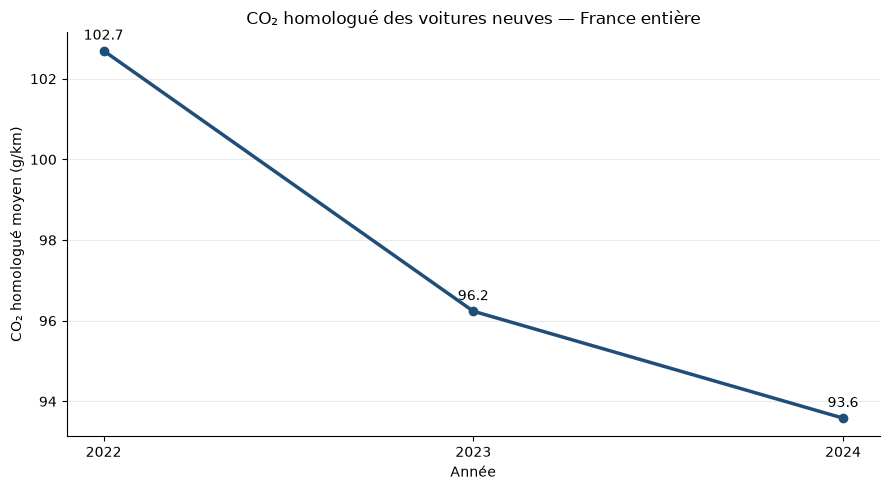

Variation 2022–2024 : -9.11 g/km


In [12]:
fig, ax = plt.subplots()
ax.plot(national_.annee, national_.co2_g_km, marker="o", linewidth=2.5, color="#1f4e79")
for _, r in national_.iterrows(): ax.annotate(f"{r.co2_g_km:.1f}", (r.annee, r.co2_g_km), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set(xticks=[2022, 2023, 2024], xlabel="Année", ylabel="CO₂ homologué moyen (g/km)",
       title="CO₂ homologué des voitures neuves — France entière")
ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()
print(f"Variation 2022–2024 : {national_.co2_g_km.iloc[-1]-national_.co2_g_km.iloc[0]:+.2f} g/km")

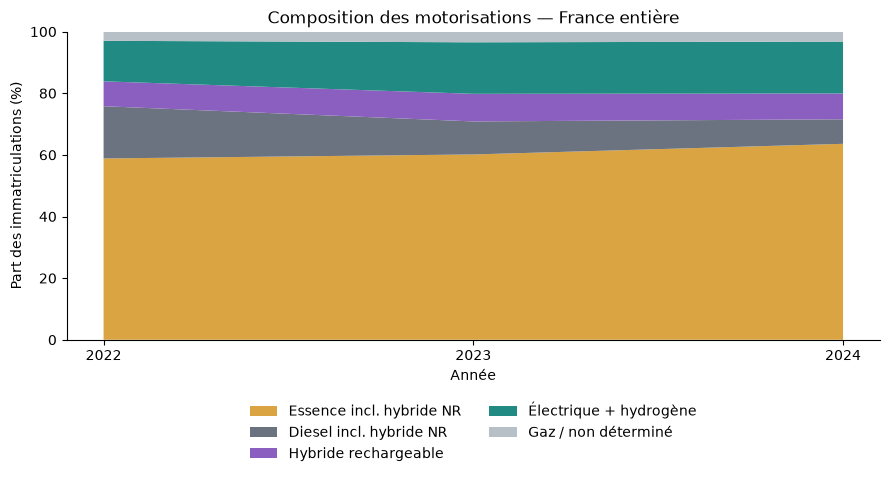

,annee,n_voitures,co2_g_km,part_essence_pct,part_diesel_pct,part_hybride_rechargeable_pct,part_electrique_hydrogene_pct,part_gaz_nd_pct
0,2022,1576946.0,102.70,58.84,16.95,8.08,13.15,2.98
1,2023,1816875.0,96.24,60.14,10.72,8.96,16.72,3.46
2,2024,1754794.0,93.58,63.59,7.96,8.38,16.84,3.23


In [13]:
parts = ["part_essence_pct", "part_diesel_pct", "part_hybride_rechargeable_pct", "part_electrique_hydrogene_pct", "part_gaz_nd_pct"]
labels = ["Essence incl. hybride NR", "Diesel incl. hybride NR", "Hybride rechargeable", "Électrique + hydrogène", "Gaz / non déterminé"]
colors = ["#d9a441", "#6b7280", "#8b5fbf", "#218b83", "#b8c0c7"]
fig, ax = plt.subplots()
ax.stackplot(national_.annee, *(national_[p] for p in parts), labels=labels, colors=colors)
ax.set(xticks=[2022, 2023, 2024], ylim=(0, 100), xlabel="Année", ylabel="Part des immatriculations (%)",
       title="Composition des motorisations — France entière")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
display(national_[["annee", "n_voitures", "co2_g_km"] + parts].round(2))

## 3. Disparités départementales

La dispersion concerne les **moyennes départementales non pondérées** : chaque département compte une fois. Les cartes montrent l'Hexagone et la Corse ; les cinq DROM sont indiqués à droite avec la même échelle de couleur.

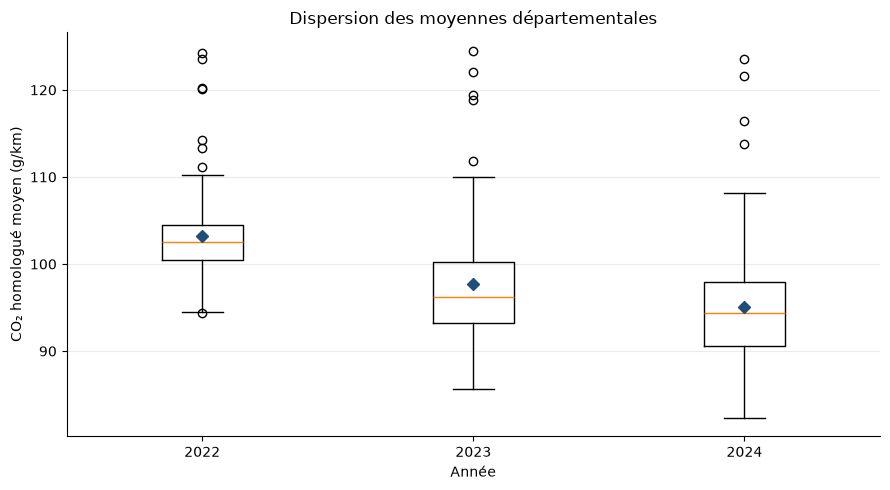

2022 : min Bouches-du-Rhône (94.4 g/km) ; max Guyane (124.2 g/km) ; écart-type 5.3 g/km
2023 : min Alpes-Maritimes (85.7 g/km) ; max Mayotte (124.5 g/km) ; écart-type 6.9 g/km
2024 : min Hauts-de-Seine (82.3 g/km) ; max Mayotte (123.6 g/km) ; écart-type 7.3 g/km


In [14]:
fig, ax = plt.subplots()
values = [tableau.loc[tableau.annee.eq(y), "co2_g_km"] for y in (2022, 2023, 2024)]
ax.boxplot(values, tick_labels=["2022", "2023", "2024"], showmeans=True,
           meanprops={"marker": "D", "markerfacecolor": "#1f4e79", "markeredgecolor": "#1f4e79"})
ax.set(xlabel="Année", ylabel="CO₂ homologué moyen (g/km)", title="Dispersion des moyennes départementales")
ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()
for y, s in tableau.groupby("annee"):
    minimum = s.loc[s.co2_g_km.idxmin()]
    maximum = s.loc[s.co2_g_km.idxmax()]
    print(f"{y} : min {minimum.departement} ({minimum.co2_g_km:.1f} g/km) ; "
          f"max {maximum.departement} ({maximum.co2_g_km:.1f} g/km) ; "
          f"écart-type {s.co2_g_km.std():.1f} g/km")

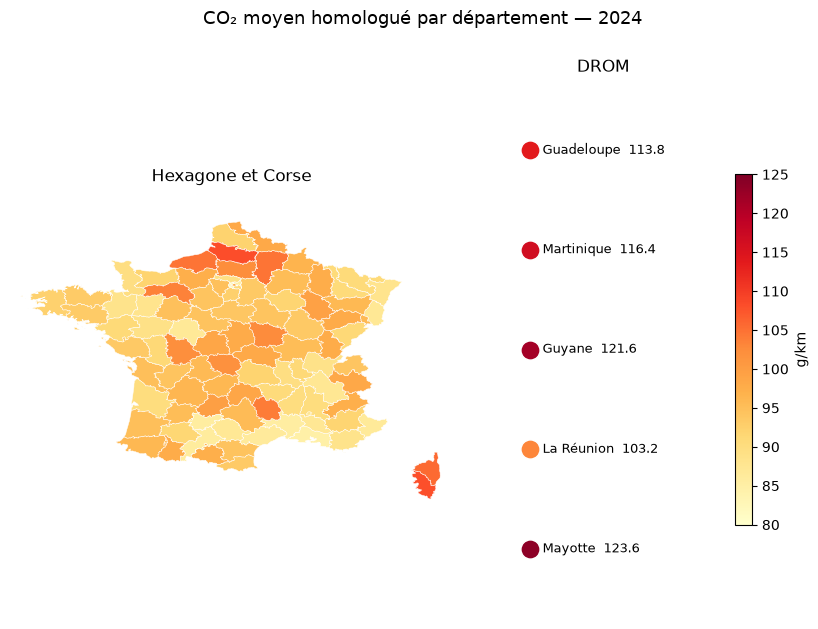

In [15]:
geo = json.loads((RAW / "departements-2024-1000m.geojson").read_text())
features = {f["properties"]["code"]: f for f in geo["features"]}
assert set(tableau.geocode_departement) <= set(features), "Départements absents du fond de carte."

def polygons(geometry):
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"][0]]
    if geometry["type"] == "MultiPolygon":
        return [piece[0] for piece in geometry["coordinates"]]
    raise ValueError(geometry["type"])

def carte_departementale(frame, variable, titre, unite, cmap, vmin, vmax):
    valeurs = frame.set_index("geocode_departement")[variable]
    norm = Normalize(vmin=vmin, vmax=vmax)
    cm = plt.colormaps[cmap]
    fig, (ax, dom) = plt.subplots(1, 2, figsize=(11, 7), gridspec_kw={"width_ratios": [4, 1.6]})
    patches, couleurs = [], []
    for code, valeur in valeurs.items():
        if len(code) == 3: continue
        for coordinates in polygons(features[code]["geometry"]):
            patches.append(Polygon(coordinates, closed=True))
            couleurs.append(valeur)
    collection = PatchCollection(patches, cmap=cm, norm=norm, edgecolor="white", linewidth=.35)
    collection.set_array(np.asarray(couleurs))
    ax.add_collection(collection)
    ax.set(xlim=(-5.5, 10), ylim=(41, 52.2), title="Hexagone et Corse")
    ax.set_aspect("equal"); ax.axis("off")
    drom = frame.loc[frame.geocode_departement.str.len().eq(3)].sort_values("geocode_departement")
    for i, row in enumerate(drom.itertuples()):
        dom.scatter([0], [i], c=[row._asdict()[variable]], cmap=cm, norm=norm, s=190, edgecolor="white")
        dom.text(.16, i, f"{row.departement}  {row._asdict()[variable]:.1f}", va="center", fontsize=9)
    dom.set(xlim=(-.2, 2.1), ylim=(-.7, 4.7), title="DROM")
    dom.invert_yaxis(); dom.axis("off")
    fig.colorbar(ScalarMappable(norm=norm, cmap=cm), ax=[ax, dom], shrink=.65, label=unite)
    fig.suptitle(titre, fontsize=13)
    plt.show()

annee_2024 = tableau.loc[tableau.annee.eq(2024)]
carte_departementale(annee_2024, "co2_g_km", "CO₂ moyen homologué par département — 2024",
                     "g/km", "YlOrRd", 80, 125)

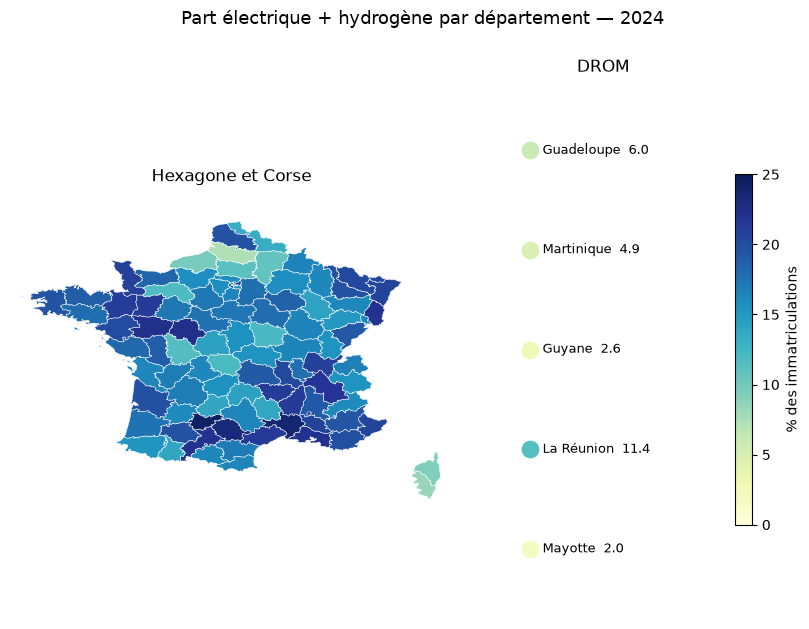

In [16]:
carte_departementale(annee_2024, "part_electrique_hydrogene_pct", "Part électrique + hydrogène par département — 2024",
                     "% des immatriculations", "YlGnBu", 0, 25)

## 4. Association entre motorisation et CO₂

Les voitures électriques n'émettent pas de CO₂ à l'échappement dans la mesure homologuée ; la catégorie publiée les regroupe avec l'hydrogène. La pente observée est donc en partie une relation de composition. Elle peut aussi refléter d'autres facteurs (poids et modèles, parts d'hybrides, contexte territorial).

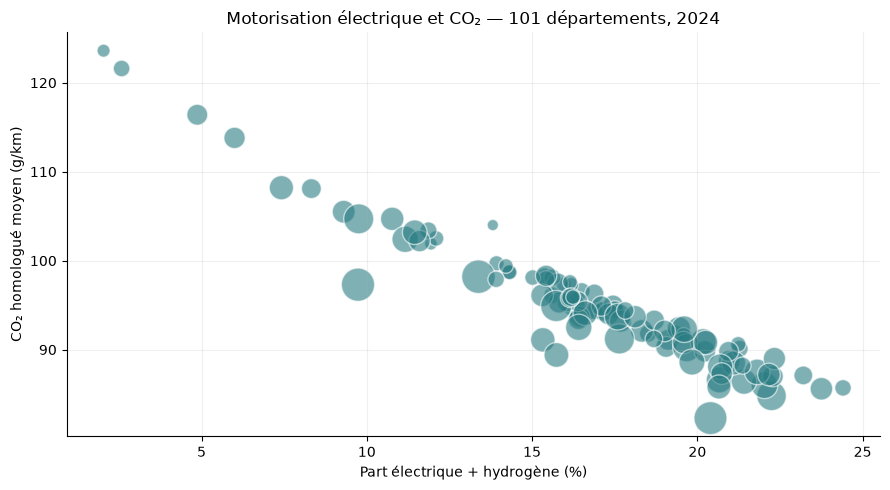

Corrélation de Pearson (101 départements, 2024) : -0.958


In [17]:
fig, ax = plt.subplots()
ax.scatter(annee_2024.part_electrique_hydrogene_pct, annee_2024.co2_g_km,
           s=np.sqrt(annee_2024.n_voitures)*2, alpha=.6, color="#287c82", edgecolor="white")
ax.set(xlabel="Part électrique + hydrogène (%)", ylabel="CO₂ homologué moyen (g/km)",
       title="Motorisation électrique et CO₂ — 101 départements, 2024")
ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
print(f"Corrélation de Pearson (101 départements, 2024) : {annee_2024.part_electrique_hydrogene_pct.corr(annee_2024.co2_g_km):.3f}")

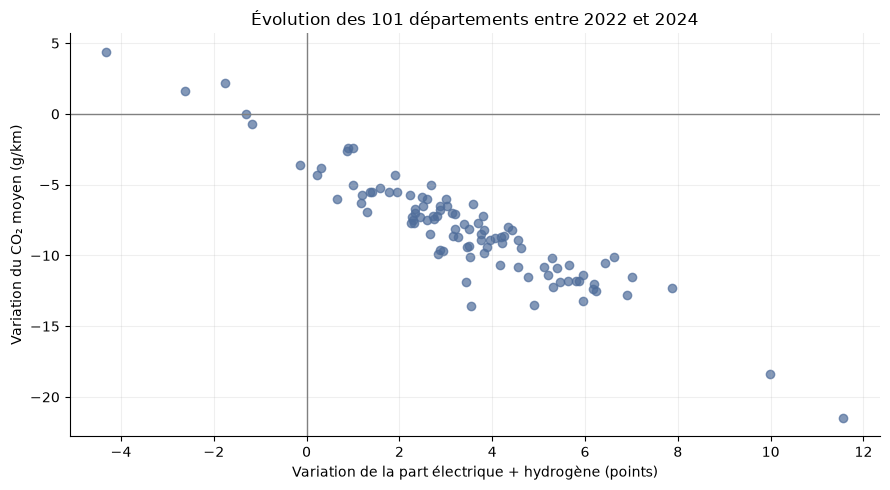

Corrélation des variations : -0.933


In [18]:
base = tableau.pivot(index="geocode_departement", columns="annee", values=["co2_g_km", "part_electrique_hydrogene_pct"])
delta = pd.DataFrame({
    "variation_part_electrique_points": base["part_electrique_hydrogene_pct"][2024] - base["part_electrique_hydrogene_pct"][2022],
    "variation_co2_g_km": base["co2_g_km"][2024] - base["co2_g_km"][2022],
})
fig, ax = plt.subplots()
ax.scatter(delta.variation_part_electrique_points, delta.variation_co2_g_km, alpha=.7, color="#4f6d9a")
ax.axhline(0, color="gray", linewidth=1); ax.axvline(0, color="gray", linewidth=1)
ax.set(xlabel="Variation de la part électrique + hydrogène (points)",
       ylabel="Variation du CO₂ moyen (g/km)", title="Évolution des 101 départements entre 2022 et 2024")
ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
print(f"Corrélation des variations : {delta.variation_part_electrique_points.corr(delta.variation_co2_g_km):.3f}")

## 5. Synthèse et limites

- **Baisse nationale :** −9,11 g/km entre 2022 et 2024, sur des années entières comparables.
- **Transition des motorisations :** la part électrique + hydrogène augmente de 3,69 points ; le diesel (avec hybrides non rechargeables) recule. Les parts nationales sont pondérées par les immatriculations.
- **Territoires :** en 2024, les Hauts-de-Seine ont la moyenne la plus basse (82,3 g/km) et Mayotte la plus haute (123,6 g/km). La dispersion entre départements s'accroît. Une moyenne départementale ne décrit pas les émissions de chaque conducteur.
- **Lecture prudente :** corrélations fortes mais non causales ; moyenne homologuée en g/km, ni émissions réelles, ni émissions du cycle de vie, ni total annuel. Le périmètre comprend les immatriculations de personnes physiques et morales.

**Plan oral (10 min) :** question et sources (1 min) ; qualité et méthode (2 min) ; évolution nationale (2 min) ; cartes et disparités (2 min) ; association et limites (2 min) ; conclusion (1 min).